# Real-to-Sim Sensor Model, Part 2: Align the Real Scan and Make the Labels
This is step 2 of the plan: put the real scan and the ideal CAD on the same pixels, then read off the two training targets for every CAD pixel.

| Part | Notebook | What it does |
|---|---|---|
| 1 | `12_1_real2sim_render` | Camera, real camera poses, CAD → 7 input maps per pixel |
| **2** | **`12_2_real2sim_labels`** | **Correct the CAD pose, then `y_drop` and `e_z` for every CAD pixel** |
| 3 | `12_3_...` | Dataset over all views and workpieces |
| 4–6 | | Model, simulator, export |

**Why the pose needs correcting first.** The CAD is placed with `T_average` (the ICP fit of the CAD to all merged scans, from `4_1`). It is tilted by ~2° and sits ~2 mm too high. Left as it is, every pixel's `e_z` would contain this placement error, and the model would learn the error instead of the sensor.

**The correction**: one rigid correction per workpiece, measured from all of its views pooled together.
1. **Tilt and height from the table.** The workpiece stands on the table, so in the CAD frame the table must be the flat plane z = 0. The real table around the workpiece is measured, and the CAD frame is tilted and shifted until it is.
2. **x, y and yaw from the top face.** Seen from above, the outline of the real top face (outer edge and pocket opening) should lie on the CAD's. It is turned (yaw = rotation about the vertical) and slid until it does.

Tilt and height come from the table, not from the workpiece, on purpose: the sensor's depth errors on the workpiece are what the model has to learn, so they must not be absorbed into the pose.

**Then the labels** (section 8), for every CAD pixel of a view:
- `y_drop` = 1 if no real point landed on the pixel, else 0
- `e_z` = real depth − CAD depth (mm), only where `y_drop` = 0

**Output:** `simulation/real2sim/{EXPERIMENT}/{WP}/T_cad_refined.npy` is the corrected CAD → robot base pose (same role as `T_average.npy`), with the numbers in a `.json` next to it. Part 3 uses it to make the labels for all views. This notebook defines the labels and checks them on a few views.

Sections: 2 compute the correction · 3 the table step · 4 the top-face step · 5 is it repeatable · 6 Check E: does one correction fit every view · 7 Check F: outline on the real images · 8 the labels · 9 Check G: do the labels behave like a depth sensor · summary.

In [1]:
# ==========================================
# 1. CONFIGURATION
# ==========================================
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import real2sim as rs

EXPERIMENT = "test_11_real_pocket"
WORKPIECE = "TH1041AV"                       # workpiece for the single-workpiece plots
ALL_WORKPIECES = ["TH1021AV", "TH1031AV", "TH1041AV", "TH1051AV"]
GRID_SCALE = 2          # 960x540 working grid (12_1 section 7.1)
GATE_MM = 10.0          # real points farther than this from the CAD depth at their pixel are not the workpiece
CHECK_STEP = 8          # per-view checks use every 8th view (36 views per workpiece)
LABEL_VIEWS = [100, 287]
SAVE_POSES = True       # write T_cad_refined.npy / .json for each workpiece

FIG_DIR = f"simulation/real2sim/{EXPERIMENT}/{WORKPIECE}"
os.makedirs(FIG_DIR, exist_ok=True)
cam_native = rs.Camera.native()
cam = cam_native.downscaled(GRID_SCALE)
raw_dir = {wp: rs.real_dirs(EXPERIMENT, wp)["raw"] for wp in ALL_WORKPIECES}
renderers = {wp: rs.CadRenderer(rs.real_dirs(EXPERIMENT, wp)["cad"]) for wp in ALL_WORKPIECES}
T_avg = {wp: rs.load_T_average(raw_dir[wp]) for wp in ALL_WORKPIECES}
views = {wp: rs.list_real_views(raw_dir[wp]) for wp in ALL_WORKPIECES}

for wp in ALL_WORKPIECES:
    print(f"{wp}: {len(views[wp])} real views")
print(f"Working grid {cam.width}x{cam.height}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
TH1021AV: 288 real views
TH1031AV: 288 real views
TH1041AV: 288 real views
TH1051AV: 288 real views
Working grid 960x540


## 2. Compute the correction (all workpieces)
For each workpiece, all of its views are moved into the CAD frame with `T_average` and pooled, then steps 1 and 2 run on the pooled points (`rs.refine_cad_pose`). This takes about 30 s per workpiece.

| Column | Meaning |
|---|---|
| `tilt_deg`, `table_z_mm` | How tilted and how high the real table is in the old CAD frame (ideal 0 and 0). Step 1 removes exactly this. |
| `table_flatness_mm` | How far 5×5 mm table patches scatter around the fitted plane. Small means the table really is flat, so it is a good reference. |
| `yaw_deg`, `shift_x_mm`, `shift_y_mm` | The step-2 turn and slide of the top face |
| `top_fattening_mm` | How much wider the real top face is than the CAD's, all around (section 4) |
| `top_iou_before`, `top_iou_after` | Overlap of the real top face with the (fattened) CAD top face seen from above (1 = identical) |
| `cad_move_mean_mm`, `cad_move_max_mm` | How far the CAD's corners and edges move between `T_average` and the corrected pose |

In [2]:
# ==========================================
# 2. COMPUTE THE CORRECTION FOR EVERY WORKPIECE
# ==========================================
T_ref, reports, extras = {}, {}, {}
for wp in ALL_WORKPIECES:
    t0 = time.time()
    T_ref[wp], reports[wp], extras[wp] = rs.refine_cad_pose(raw_dir[wp], renderers[wp], T_avg[wp], views[wp])
    msg = f"{wp}: {len(views[wp])} views pooled in {time.time() - t0:.0f} s"
    if SAVE_POSES:
        msg += f" -> saved {rs.save_refined_pose(EXPERIMENT, wp, T_ref[wp], reports[wp])}"
    print(msg)

df_pose = pd.DataFrame(reports).T.rename(columns={"table_tilt_deg": "tilt_deg"})
display(df_pose[["tilt_deg", "table_z_mm", "table_flatness_mm", "yaw_deg", "shift_x_mm", "shift_y_mm", "top_fattening_mm",
                 "top_iou_before", "top_iou_after", "cad_move_mean_mm", "cad_move_max_mm"]].astype(float).round(3))

TH1021AV: 288 views pooled in 81 s -> saved simulation/real2sim/test_11_real_pocket/TH1021AV/T_cad_refined.npy
TH1031AV: 288 views pooled in 74 s -> saved simulation/real2sim/test_11_real_pocket/TH1031AV/T_cad_refined.npy
TH1041AV: 288 views pooled in 88 s -> saved simulation/real2sim/test_11_real_pocket/TH1041AV/T_cad_refined.npy
TH1051AV: 288 views pooled in 74 s -> saved simulation/real2sim/test_11_real_pocket/TH1051AV/T_cad_refined.npy


,tilt_deg,table_z_mm,table_flatness_mm,yaw_deg,shift_x_mm,shift_y_mm,top_fattening_mm,top_iou_before,top_iou_after,cad_move_mean_mm,cad_move_max_mm
TH1021AV,1.977,-2.107,0.175,-0.871,1.142,0.473,2.5,0.840,0.866,2.272,3.766
TH1031AV,2.592,-1.999,0.198,-1.777,1.738,0.469,2.5,0.847,0.905,2.371,5.039
TH1041AV,2.237,-1.992,0.191,-0.240,1.027,-0.648,3.0,0.891,0.913,2.171,3.484
TH1051AV,1.712,-3.101,0.171,-2.484,0.840,-0.586,3.0,0.915,0.932,3.506,5.455


## 3. Step 1: the table
Each square is a 5×5 mm patch of real table around the workpiece (black outline), coloured by its median height in the CAD frame.
- **Left, with `T_average`:** the colour runs from one side to the other (the tilt), and the whole table sits below 0 (the height error).
- **Right, after the correction:** flat and centred on 0.

Patches marked × were left out of the fit as outliers, for example the halo the sensor leaves next to the workpiece.

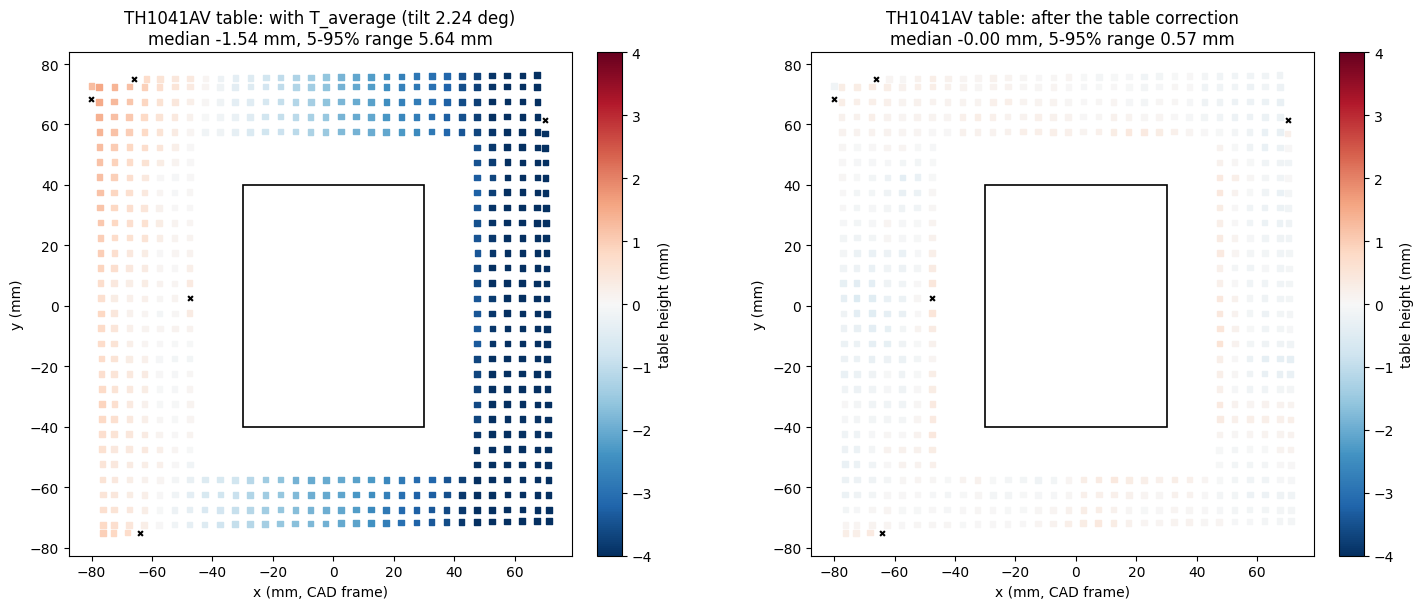

In [3]:
# ==========================================
# 3. STEP 1: TABLE HEIGHT BEFORE / AFTER
# ==========================================
tab = extras[WORKPIECE]["table"]
lo, hi = rs.cad_bounds(renderers[WORKPIECE])
used = tab["patch_used"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, h, title in [(axes[0], tab["patch_z"], f"with T_average (tilt {reports[WORKPIECE]['table_tilt_deg']:.2f} deg)"),
                     (axes[1], tab["patch_residual"], "after the table correction")]:
    sc = ax.scatter(tab["patch_x"][used], tab["patch_y"][used], c=h[used], cmap="RdBu_r", vmin=-4, vmax=4, s=16, marker="s")
    ax.scatter(tab["patch_x"][~used], tab["patch_y"][~used], c="k", s=12, marker="x")
    ax.add_patch(plt.Rectangle((lo[0], lo[1]), hi[0] - lo[0], hi[1] - lo[1], fill=False, ec="k", lw=1.2))
    p5, p95 = np.percentile(h[used], [5, 95])
    ax.set_title(f"{WORKPIECE} table: {title}\nmedian {np.median(h[used]):+.2f} mm, 5-95% range {p95 - p5:.2f} mm")
    ax.set_aspect("equal")
    ax.set_xlabel("x (mm, CAD frame)")
    ax.set_ylabel("y (mm)")
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04, label="table height (mm)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part2_table_before_after.png"), dpi=110)
plt.show()

## 4. Step 2: the top face seen from above
The real top-face points (after step 1) are drawn from above on a 0.25 mm grid and compared with the CAD's top face. **Grey** = both, **red** = CAD only, **blue** = real only.

One thing to know first: the real top face comes out **wider** than the CAD's, by `top_fattening_mm` (about 2–2.5 mm) all around. The sensor smears depth across the top edges, and pooling ~288 views adds a little blur. So the CAD face is compared in a grown version (dashed line). Otherwise any slide smaller than the fattening would fit equally well, and the correction could not be measured.
- **Before:** the blue band is thicker on some sides than others, and red shows where the CAD sticks out. That is the offset.
- **After** turning by `yaw_deg` and sliding by (`shift_x_mm`, `shift_y_mm`): the blue band is about even all around.
- **Right:** the overlap for each trial yaw (after the best slide at that yaw). The peak is the yaw correction. It is broad, so yaw is the least certain part of the correction (section 5 checks how repeatable it is).

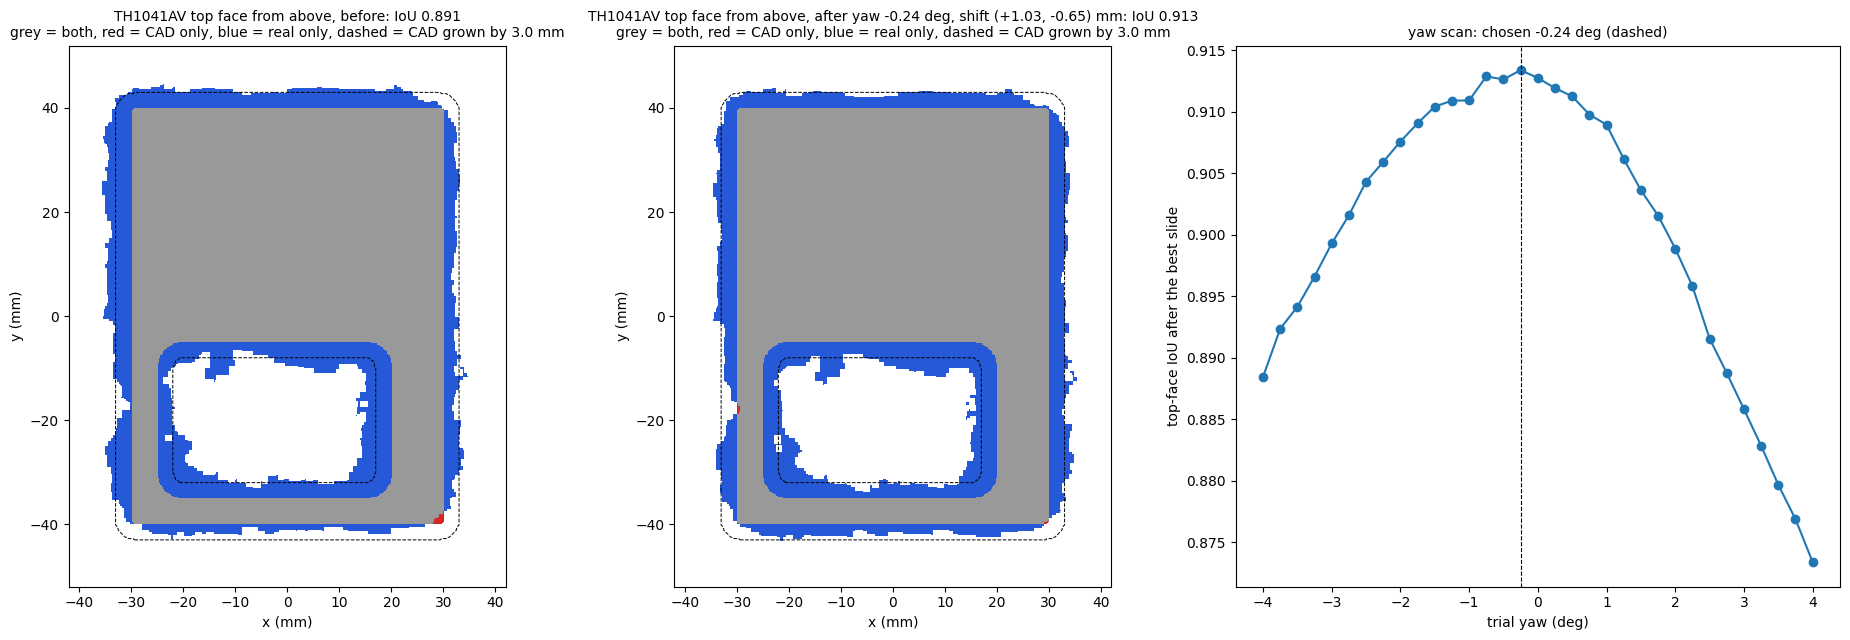

In [4]:
# ==========================================
# 4. STEP 2: TOP FACE FROM ABOVE, BEFORE / AFTER + YAW SCAN
# ==========================================
sh = extras[WORKPIECE]["shift"]
rep = reports[WORKPIECE]
x0, x1, y0, y1 = sh["extent"]
before = rs.rasterize_xy(extras[WORKPIECE]["top_points"], x0, y0, sh["cad"].shape)   # no turn, no slide


def overlap_image(real, cad):
    img = np.ones(cad.shape + (3,))
    img[cad & real] = (0.6, 0.6, 0.6)
    img[cad & ~real] = (0.85, 0.15, 0.15)
    img[~cad & real] = (0.15, 0.35, 0.85)
    return img


fig, axes = plt.subplots(1, 3, figsize=(19, 6.5), gridspec_kw=dict(width_ratios=[1, 1, 1.15]))
for ax, real, title in [(axes[0], before, f"before: IoU {sh['iou_before']:.3f}"),
                        (axes[1], sh["real_after"], f"after yaw {rep['yaw_deg']:+.2f} deg, shift "
                                                    f"({rep['shift_x_mm']:+.2f}, {rep['shift_y_mm']:+.2f}) mm: IoU {sh['iou_after']:.3f}")]:
    ax.imshow(overlap_image(real, sh["cad"]), origin="lower", extent=sh["extent"], interpolation="nearest")
    ax.contour(sh["cad_grown"].astype(float), levels=[0.5], origin="lower", extent=sh["extent"], colors="k",
               linewidths=0.7, linestyles="--")
    ax.set_title(f"{WORKPIECE} top face from above, {title}\n"
                 f"grey = both, red = CAD only, blue = real only, "
                 f"dashed = CAD grown by {sh['grow_mm']:.1f} mm", fontsize=10)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")

yaws, iou_yaw = sh["yaw_scan"]
axes[2].plot(yaws, iou_yaw, "o-")
axes[2].axvline(rep["yaw_deg"], color="k", lw=0.8, ls="--")
axes[2].set_xlabel("trial yaw (deg)")
axes[2].set_ylabel("top-face IoU after the best slide")
axes[2].set_title(f"yaw scan: chosen {rep['yaw_deg']:+.2f} deg (dashed)", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part2_topface_before_after.png"), dpi=110)
plt.show()

## 5. Is the correction repeatable?
The correction is computed twice more: once from the even-numbered views only, once from the odd-numbered views only. If the two halves agree, the correction is a measurement, not noise.

`placement_diff` is how far the CAD's vertices end up apart between the two halves (mean / max over the mesh). This takes about 1 minute per workpiece.

In [5]:
# ==========================================
# 5. REPEATABILITY: EVEN VIEWS VS ODD VIEWS
# ==========================================
rows = []
for wp in ALL_WORKPIECES:
    T_e, rep_e, _ = rs.refine_cad_pose(raw_dir[wp], renderers[wp], T_avg[wp], views[wp][::2])
    T_o, rep_o, _ = rs.refine_cad_pose(raw_dir[wp], renderers[wp], T_avg[wp], views[wp][1::2])
    V = np.asarray(renderers[wp].mesh.vertices)
    gap = np.linalg.norm(rs.transform_points(V, T_e) - rs.transform_points(V, T_o), axis=1)
    rows.append(dict(workpiece=wp,
                     tilt_even=rep_e["table_tilt_deg"], tilt_odd=rep_o["table_tilt_deg"],
                     table_z_even=rep_e["table_z_mm"], table_z_odd=rep_o["table_z_mm"],
                     yaw_even=rep_e["yaw_deg"], yaw_odd=rep_o["yaw_deg"],
                     shift_x_even=rep_e["shift_x_mm"], shift_x_odd=rep_o["shift_x_mm"],
                     shift_y_even=rep_e["shift_y_mm"], shift_y_odd=rep_o["shift_y_mm"],
                     placement_diff_mean_mm=gap.mean(), placement_diff_max_mm=gap.max()))
df_rep = pd.DataFrame(rows).set_index("workpiece")
display(df_rep.round(3))

,tilt_even,tilt_odd,table_z_even,table_z_odd,yaw_even,yaw_odd,shift_x_even,shift_x_odd,shift_y_even,shift_y_odd,placement_diff_mean_mm,placement_diff_max_mm
workpiece,,,,,,,,,,,,
TH1021AV,1.986,1.969,-2.100,-2.115,-0.821,-0.559,1.140,1.220,0.419,0.460,0.208,0.326
TH1031AV,2.599,2.586,-2.001,-1.999,-1.837,-1.336,1.828,1.680,0.242,0.582,0.435,0.766
TH1041AV,2.239,2.238,-1.995,-1.991,-0.166,-0.256,1.043,1.135,-0.784,-1.045,0.272,0.344
TH1051AV,1.711,1.714,-3.090,-3.104,-2.345,-2.177,0.953,0.875,-0.802,-0.479,0.340,0.466


## 6. Check E: does one correction fit every view?
One correction is used for all ~288 views of a workpiece. That only works if the views agree with each other, i.e. the robot reports the camera pose consistently. Every 8th view is checked on its own, with `T_average` and with the corrected pose:

| Column | Meaning |
|---|---|
| `table_tilt_deg`, `table_z_mm` | That view's own table plane (ideal 0 and 0). The spread across views shows how consistent the views are. |
| `top_z_mm` | Median height of that view's top-face points (CAD top = 40) |
| `outline_iou` | Overlap in the image between the CAD's raised part and the real one. Higher is better; the sensor's edge effects keep it below 1. |

Tilt is always ≥ 0, so per-view noise alone gives a mean of about 0.2°.

table_tilt_deg        table_z_mm        top_z_mm         \
                              mean    std       mean    std     mean    std   
workpiece pose                                                                
TH1021AV  T_average          1.951  0.239     -2.206  0.254   38.100  0.329   
          corrected          0.226  0.153     -0.103  0.252   39.201  0.492   
TH1031AV  T_average          2.598  0.193     -2.131  0.197   38.220  0.543   
          corrected          0.209  0.118     -0.130  0.195   39.309  0.469   
TH1041AV  T_average          2.227  0.197     -2.128  0.221   38.474  0.459   
          corrected          0.215  0.123     -0.140  0.225   39.494  0.423   
TH1051AV  T_average          1.686  0.189     -3.198  0.229   37.961  0.515   
          corrected          0.218  0.119     -0.094  0.234   39.465  0.447   

                    outline_iou         
                           mean    std  
workpiece pose                          
TH1021AV  T_average       0.783  0.050  
          corrected       0.810  0.046  
TH1031AV  T_average       0.788  0.050  
          corrected       0.806  0.051  
TH1041AV  T_average       0.796  0.053  
          corrected       0.818  0.044  
TH1051AV  T_average       0.811  0.047  
          corrected       0.824  0.043

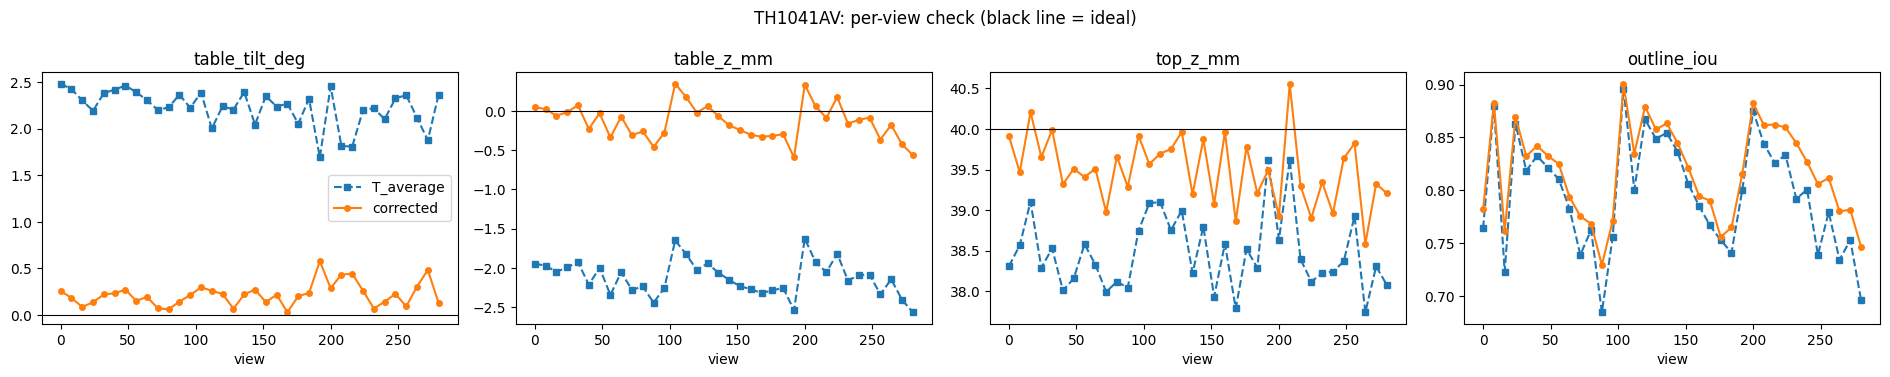

In [6]:
# ==========================================
# 6. CHECK E: EACH VIEW ON ITS OWN, T_average VS CORRECTED
# ==========================================
rows = []
for wp in ALL_WORKPIECES:
    for v in views[wp][::CHECK_STEP]:
        for pose, T in [("T_average", T_avg[wp]), ("corrected", T_ref[wp])]:
            r = rs.view_pose_check(raw_dir[wp], v, renderers[wp], cam, T)
            r.update(workpiece=wp, pose=pose)
            rows.append(r)
df_check = pd.DataFrame(rows)
cols = ["table_tilt_deg", "table_z_mm", "top_z_mm", "outline_iou"]
display(df_check.groupby(["workpiece", "pose"])[cols].agg(["mean", "std"]).round(3))

d = df_check[df_check.workpiece == WORKPIECE]
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, col, ideal in zip(axes, cols, [0, 0, 40, None]):
    for pose, style in [("T_average", "s--"), ("corrected", "o-")]:
        dp = d[d.pose == pose]
        ax.plot(dp["view"], dp[col], style, ms=4, label=pose)
    if ideal is not None:
        ax.axhline(ideal, color="k", lw=0.8)
    ax.set_xlabel("view")
    ax.set_title(col)
axes[0].legend()
fig.suptitle(f"{WORKPIECE}: per-view check (black line = ideal)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part2_per_view_check.png"), dpi=110)
plt.show()

## 7. Check F: CAD outline on the real images, before and after
Same as 12_1 Check C, with both poses: **red** = CAD edges with `T_average`, **green** = with the corrected pose, at the native 1920×1080 grid. The CAD moves by only a few pixels, so look closely at the outer edges and the pocket rim. Green should sit on the real edges at least as well as red.

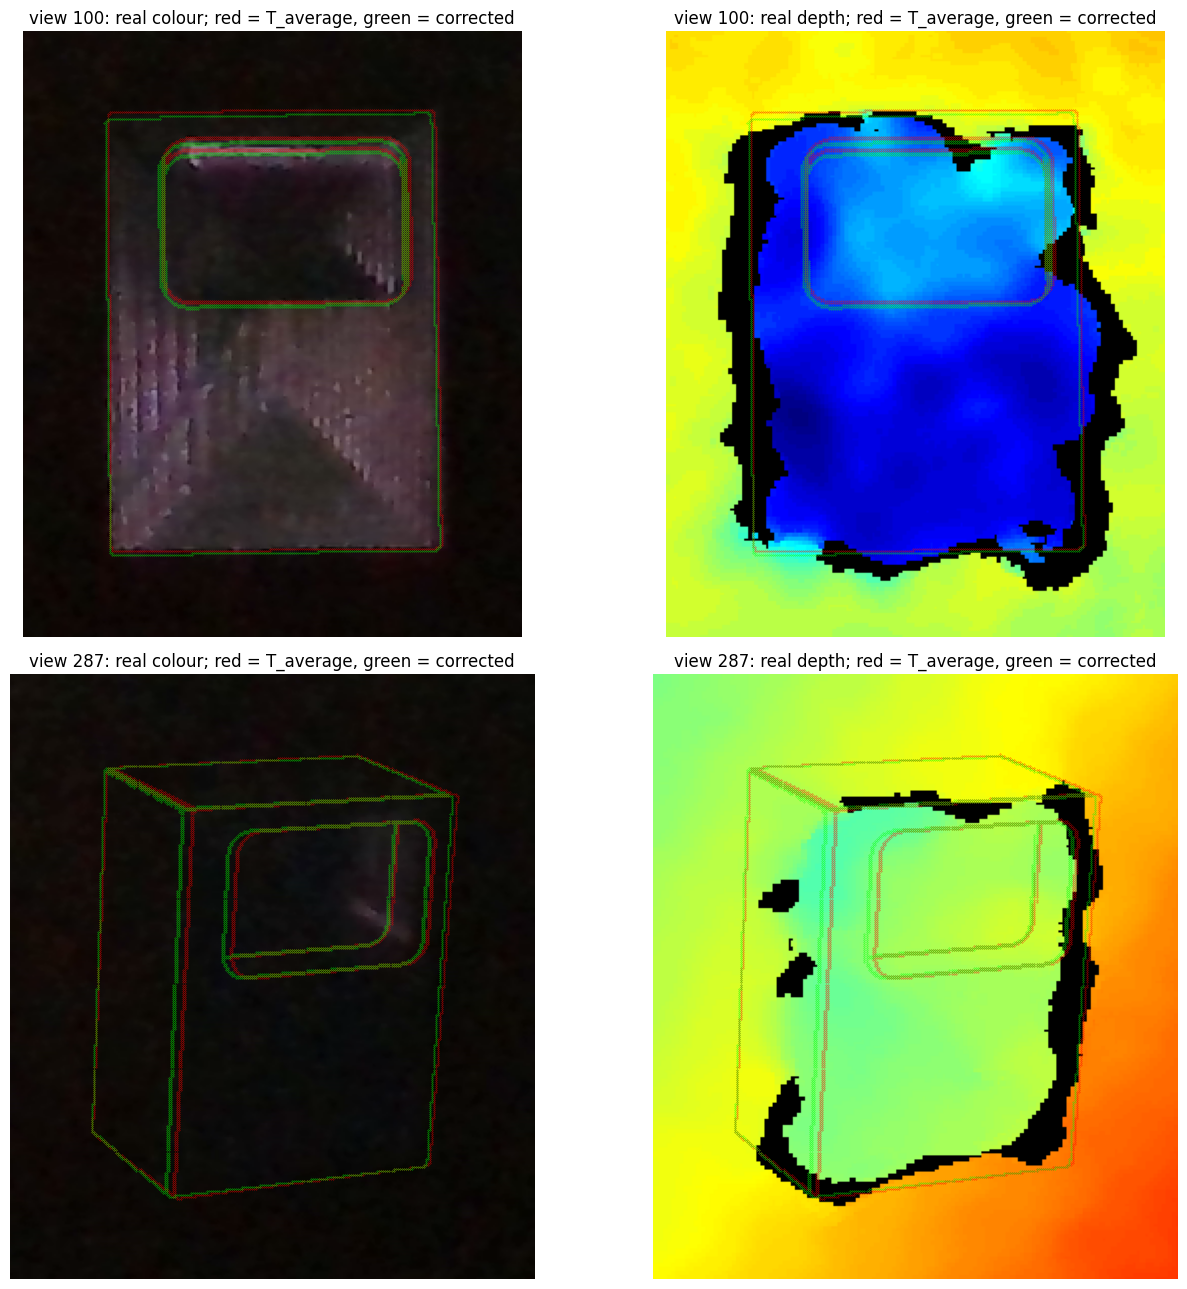

In [7]:
# ==========================================
# 7. CHECK F: CAD EDGES BEFORE (red) / AFTER (green) ON THE REAL IMAGES
# ==========================================
OVERLAY_VIEWS = [100, 287]
fig, axes = plt.subplots(len(OVERLAY_VIEWS), 2, figsize=(14, 6.5 * len(OVERLAY_VIEWS)))
for row, v in enumerate(OVERLAY_VIEWS):
    viz = cv2.cvtColor(cv2.imread(os.path.join(raw_dir[WORKPIECE], f"view{v}_viz.png")), cv2.COLOR_BGR2RGB)
    edges = {}
    for pose, T in [("T_average", T_avg[WORKPIECE]), ("corrected", T_ref[WORKPIECE])]:
        r = renderers[WORKPIECE].render(cam_native, rs.real_camera_pose(raw_dir[WORKPIECE], v, T))
        edges[pose] = rs.cad_edges(r)
    b0, b1, a0, a1 = rs.mask_bbox(r["mask"], margin=40)
    for col, (img, title) in enumerate([(viz[:, :rs.NATIVE_WIDTH], "colour"), (viz[:, rs.NATIVE_WIDTH:], "depth")]):
        ax = axes[row, col]
        ax.imshow(img[b0:b1, a0:a1])
        for pose, colour in [("T_average", "red"), ("corrected", "lime")]:
            ys, xs = np.nonzero(edges[pose][b0:b1, a0:a1])
            ax.scatter(xs, ys, s=0.2, c=colour, marker=".", label=pose)
        ax.set_title(f"view {v}: real {title}; red = T_average, green = corrected")
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part2_overlay_before_after.png"), dpi=110)
plt.show()

## 8. The labels: `y_drop` and `e_z`
The pairing rule (`rs.make_labels`):
1. Render the CAD with the corrected pose. That gives the CAD depth for every pixel: the "ideal".
2. Project every real point of the view onto its pixel (same camera, same grid).
3. Ignore real points more than `GATE_MM` (10 mm) from the CAD depth at their pixel: table, background, stray points.
4. For each CAD pixel: if no point is left, `y_drop = 1`. Otherwise `y_drop = 0` and `e_z` = (median real depth of its points) − (CAD depth).

`e_z > 0` means the real surface reads **farther** from the camera than the CAD.

**Panels.** Top row: CAD depth, real depth and `y_drop` (grey = kept, red = dropped). Bottom row: `e_z` with `T_average` and with the corrected pose, and both distributions. With `T_average`, most of the map is red (≈ +2–3 mm everywhere): that is the placement error. After the correction, it is centred on 0, and what remains is the sensor.

view 100: 9049 CAD pixels | y_drop = 1 on 17.9% (T_average: 18.0%) | e_z median +0.17 mm (T_average: +2.07 mm), 10-90% -4.47 .. +4.51 mm


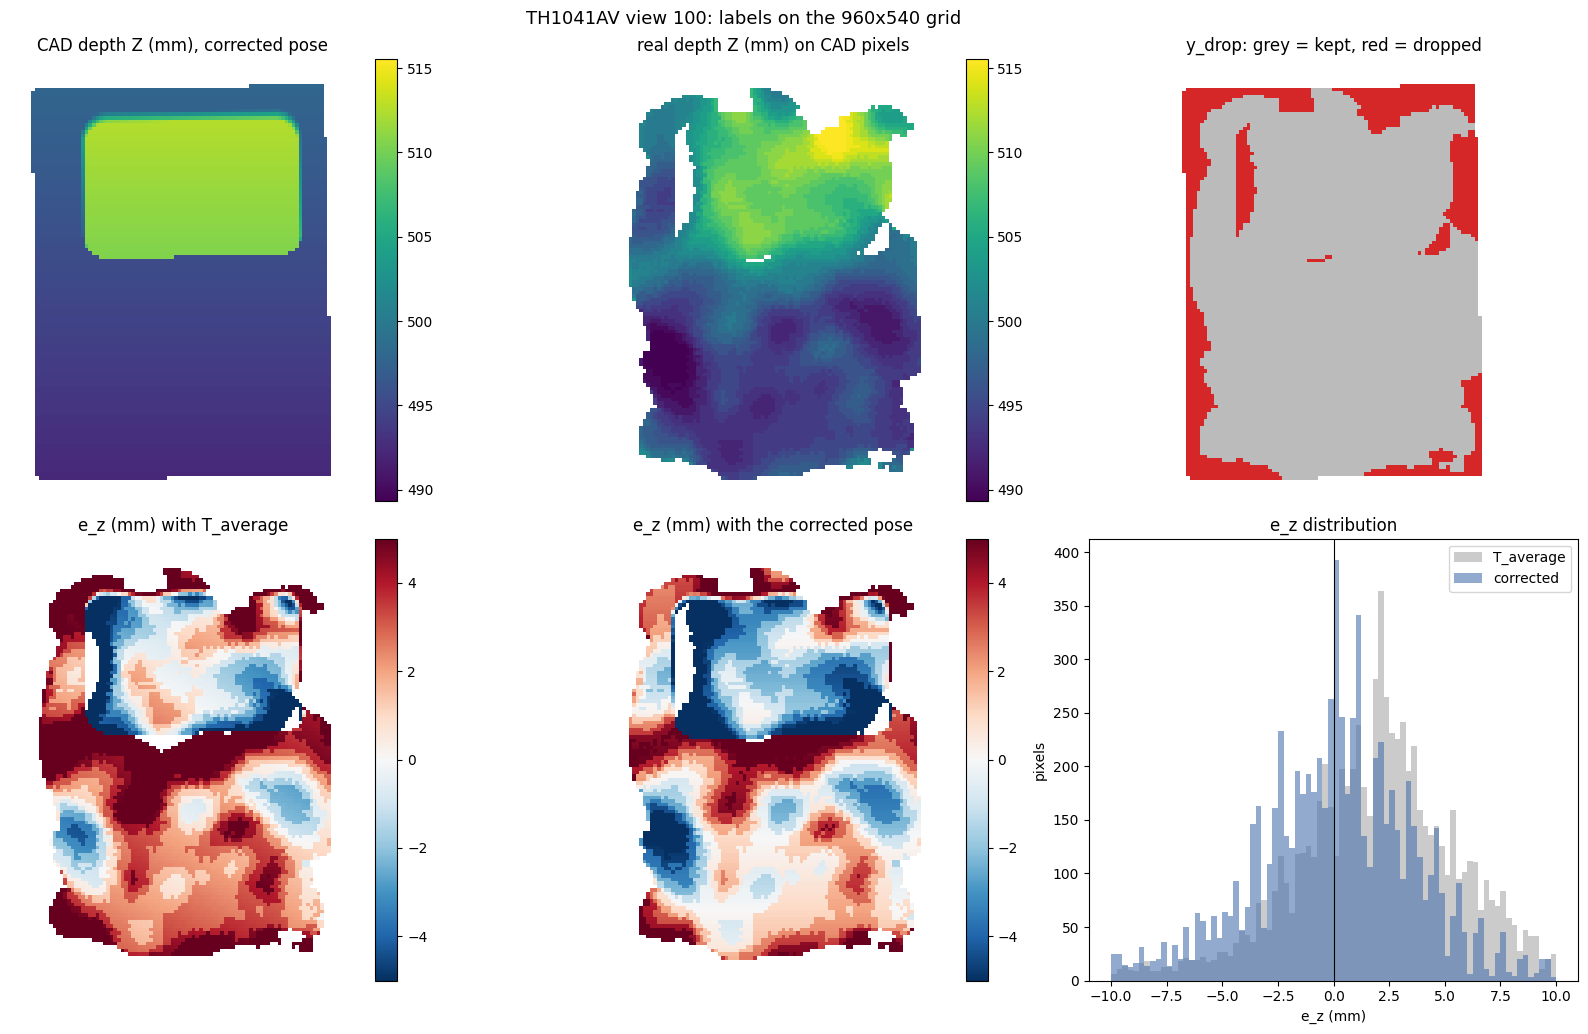

view 287: 8693 CAD pixels | y_drop = 1 on 26.3% (T_average: 31.6%) | e_z median +1.52 mm (T_average: +3.53 mm), 10-90% -1.81 .. +7.07 mm


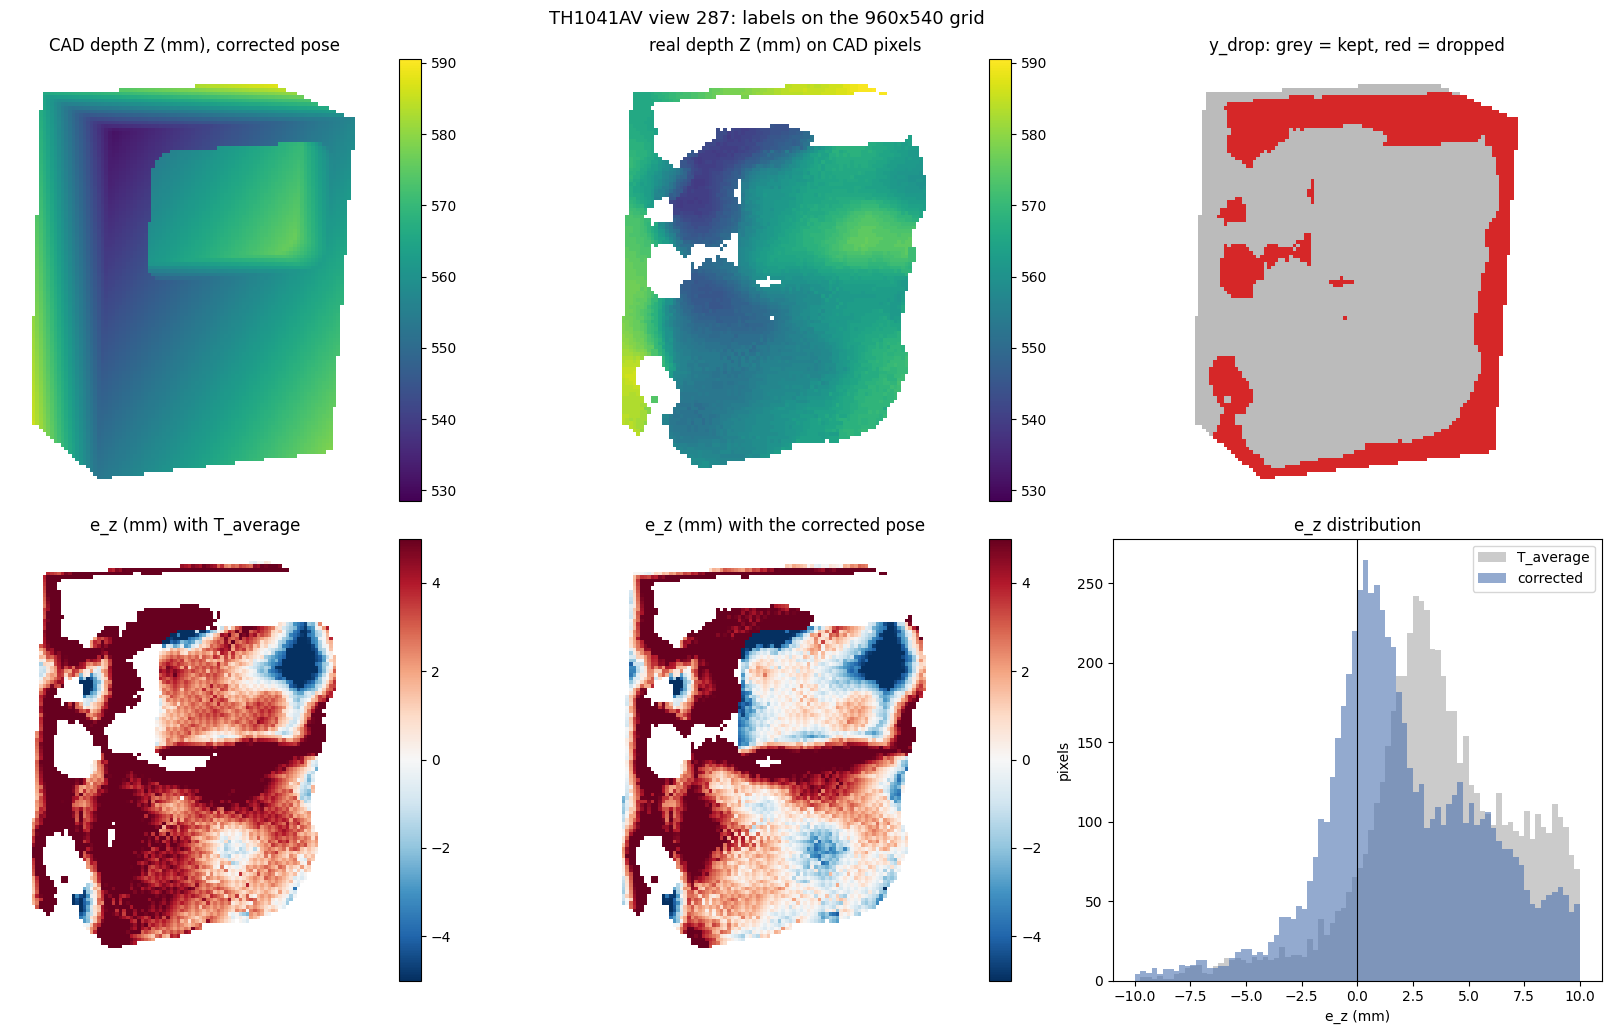

In [8]:
# ==========================================
# 8. LABELS FOR A FEW VIEWS
# ==========================================
for v in LABEL_VIEWS:
    P = rs.load_real_scan_cam(raw_dir[WORKPIECE], v)
    out = {}
    for pose, T in [("T_average", T_avg[WORKPIECE]), ("corrected", T_ref[WORKPIECE])]:
        r = renderers[WORKPIECE].render(cam, rs.real_camera_pose(raw_dir[WORKPIECE], v, T))
        out[pose] = (r, rs.make_labels(cam, r, P, GATE_MM))
    r, L = out["corrected"]
    L_old = out["T_average"][1]
    m = r["mask"]
    print(f"view {v}: {m.sum()} CAD pixels | y_drop = 1 on {np.nanmean(L['y_drop']) * 100:.1f}% "
          f"(T_average: {np.nanmean(L_old['y_drop']) * 100:.1f}%) | e_z median {np.nanmedian(L['e_z']):+.2f} mm "
          f"(T_average: {np.nanmedian(L_old['e_z']):+.2f} mm), 10-90% {np.nanpercentile(L['e_z'], 10):+.2f} .. "
          f"{np.nanpercentile(L['e_z'], 90):+.2f} mm")

    b0, b1, a0, a1 = rs.mask_bbox(m | out["T_average"][0]["mask"], margin=6)
    crop = (slice(b0, b1), slice(a0, a1))
    z_lo, z_hi = np.nanmin(r["z"]) - 3, np.nanmax(r["z"]) + 3
    fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
    panels = [  # (axis, image, colormap, vmin, vmax, colorbar, title)
        (axes[0, 0], r["z"], "viridis", z_lo, z_hi, True, "CAD depth Z (mm), corrected pose"),
        (axes[0, 1], L["z_real"], "viridis", z_lo, z_hi, True, "real depth Z (mm) on CAD pixels"),
        (axes[0, 2], L["y_drop"], ListedColormap(["#bbbbbb", "#d62728"]), 0, 1, False, "y_drop: grey = kept, red = dropped"),
        (axes[1, 0], L_old["e_z"], "RdBu_r", -5, 5, True, "e_z (mm) with T_average"),
        (axes[1, 1], L["e_z"], "RdBu_r", -5, 5, True, "e_z (mm) with the corrected pose"),
    ]
    for ax, img, cmap, lo_, hi_, colorbar, title in panels:
        im = ax.imshow(img[crop], cmap=cmap, vmin=lo_, vmax=hi_, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")
        if colorbar:
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    bins = np.arange(-10, 10.01, 0.25)
    axes[1, 2].hist(L_old["e_z"][np.isfinite(L_old["e_z"])], bins=bins, alpha=0.5, label="T_average", color="#999999")
    axes[1, 2].hist(L["e_z"][np.isfinite(L["e_z"])], bins=bins, alpha=0.6, label="corrected", color="#4C72B0")
    axes[1, 2].axvline(0, color="k", lw=0.8)
    axes[1, 2].set_xlabel("e_z (mm)")
    axes[1, 2].set_ylabel("pixels")
    axes[1, 2].legend()
    axes[1, 2].set_title("e_z distribution")
    fig.suptitle(f"{WORKPIECE} view {v}: labels on the {cam.width}x{cam.height} grid", fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"part2_labels_view{v}.png"), dpi=110)
    plt.show()

## 9. Check G: do the labels behave like a depth sensor?
Labels from every 8th view of all four workpieces (corrected pose) are pooled, and checked for the patterns a structured-light/stereo sensor should show, which are exactly what the model has to learn:
- **Left:** dropouts become more common as the surface turns away from the camera (larger angle of incidence).
- **Middle:** dropouts concentrate near CAD edges (silhouette, creases, pocket rim).
- **Right:** `e_z` spreads more at larger angles.

If these patterns were missing, or very different between workpieces, the labels or the alignment would be suspect.

1475877 CAD pixels from 144 views | y_drop = 1 on 23.4% | e_z median +0.68 mm, 10-90% -3.13 .. +5.33 mm


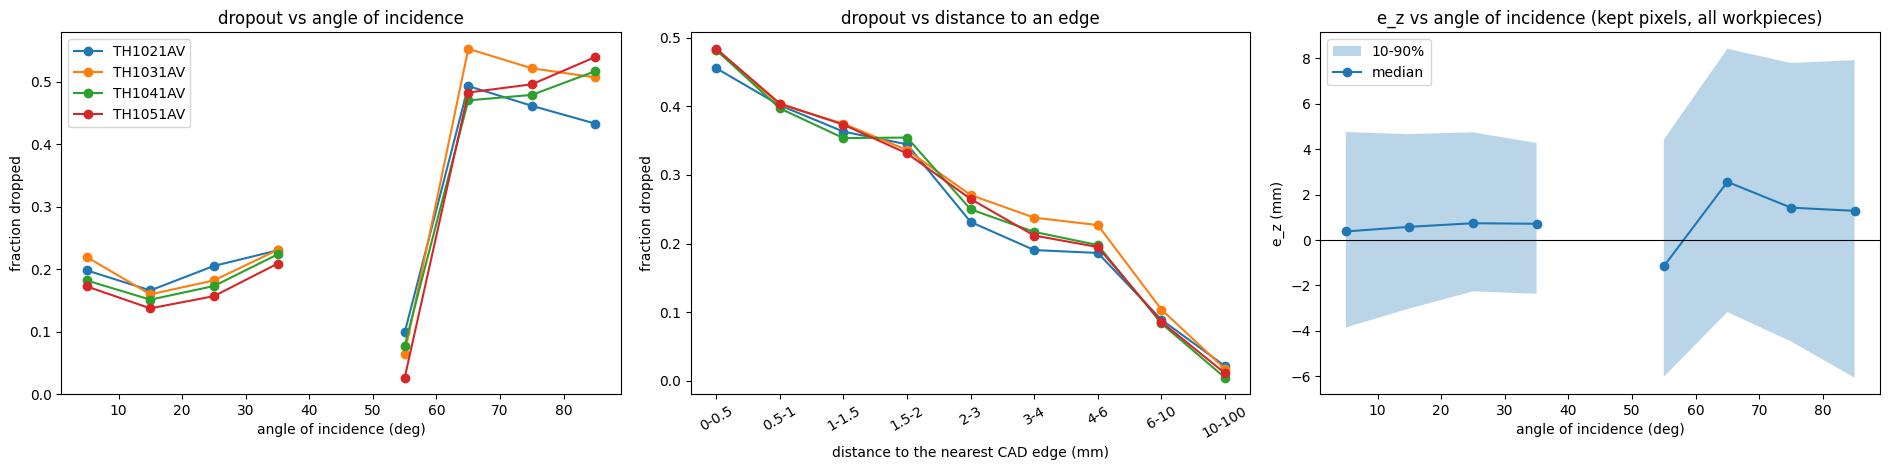

,pixels,drop_rate,ez_median,ez_p10,ez_p90
theta_bin,,,,,
"(-0.001, 10.0]",297217,0.193,0.376,-3.844,4.749
"(10.0, 20.0]",408060,0.153,0.580,-3.013,4.659
"(20.0, 30.0]",363597,0.179,0.739,-2.259,4.737
"(30.0, 40.0]",133142,0.223,0.715,-2.362,4.266
"(40.0, 50.0]",0,NaN,NaN,NaN,NaN
"(50.0, 60.0]",10551,0.075,-1.158,-6.018,4.418
"(60.0, 70.0]",140343,0.500,2.558,-3.170,8.412
"(70.0, 80.0]",86289,0.489,1.424,-4.459,7.785
"(80.0, 90.0]",36678,0.495,1.283,-6.056,7.915


In [9]:
# ==========================================
# 9. CHECK G: LABEL STATISTICS VS ANGLE AND EDGE DISTANCE
# ==========================================
pix = []
for wp in ALL_WORKPIECES:
    for v in views[wp][::CHECK_STEP]:
        r = renderers[wp].render(cam, rs.real_camera_pose(raw_dir[wp], v, T_ref[wp]))
        m = r["mask"]
        L = rs.make_labels(cam, r, rs.load_real_scan_cam(raw_dir[wp], v), GATE_MM)
        mm_per_px = np.nanmedian(r["z"]) / cam.fx
        edge_mm = cv2.distanceTransform((~rs.cad_edges(r)).astype(np.uint8), cv2.DIST_L2, 3) * mm_per_px
        pix.append(pd.DataFrame(dict(workpiece=wp, view=v, theta=r["theta_inc"][m], edge_mm=edge_mm[m],
                                     y_drop=L["y_drop"][m], e_z=L["e_z"][m])))
df_pix = pd.concat(pix, ignore_index=True)
print(f"{len(df_pix)} CAD pixels from {df_pix.groupby(['workpiece', 'view']).ngroups} views | "
      f"y_drop = 1 on {df_pix.y_drop.mean() * 100:.1f}% | e_z median {df_pix.e_z.median():+.2f} mm, "
      f"10-90% {df_pix.e_z.quantile(0.1):+.2f} .. {df_pix.e_z.quantile(0.9):+.2f} mm")

theta_bins = np.arange(0, 91, 10)
edge_bins = np.array([0, 0.5, 1, 1.5, 2, 3, 4, 6, 10, 100])
df_pix["theta_bin"] = pd.cut(df_pix.theta, theta_bins, include_lowest=True)
df_pix["edge_bin"] = pd.cut(df_pix.edge_mm, edge_bins, include_lowest=True)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for wp in ALL_WORKPIECES:
    dw = df_pix[df_pix.workpiece == wp]
    axes[0].plot(theta_bins[:-1] + 5, dw.groupby("theta_bin", observed=False).y_drop.mean(), "o-", label=wp)
    axes[1].plot(range(len(edge_bins) - 1), dw.groupby("edge_bin", observed=False).y_drop.mean(), "o-", label=wp)
axes[0].set_xlabel("angle of incidence (deg)")
axes[0].set_ylabel("fraction dropped")
axes[0].set_title("dropout vs angle of incidence")
axes[0].legend()
axes[1].set_xticks(range(len(edge_bins) - 1))
axes[1].set_xticklabels([f"{a:g}-{b:g}" for a, b in zip(edge_bins[:-1], edge_bins[1:])], rotation=30)
axes[1].set_xlabel("distance to the nearest CAD edge (mm)")
axes[1].set_ylabel("fraction dropped")
axes[1].set_title("dropout vs distance to an edge")

g = df_pix.groupby("theta_bin", observed=False).e_z
q10, q50, q90 = g.quantile(0.1), g.median(), g.quantile(0.9)
x = theta_bins[:-1] + 5
axes[2].fill_between(x, q10, q90, alpha=0.3, label="10-90%")
axes[2].plot(x, q50, "o-", label="median")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xlabel("angle of incidence (deg)")
axes[2].set_ylabel("e_z (mm)")
axes[2].set_title("e_z vs angle of incidence (kept pixels, all workpieces)")
axes[2].legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part2_label_statistics.png"), dpi=110)
plt.show()

display(df_pix.groupby("theta_bin", observed=False).agg(pixels=("y_drop", "size"), drop_rate=("y_drop", "mean"),
                                                       ez_median=("e_z", "median"),
                                                       ez_p10=("e_z", lambda s: s.quantile(0.1)),
                                                       ez_p90=("e_z", lambda s: s.quantile(0.9))).round(3))

## Summary of Part 2 (results on test_11_real_pocket)
- **Correction** (per workpiece, all 288 views pooled): removes tilt of 1.7–2.6° and table height of −2.0 to −3.1 mm (the table is flat to ~0.2 mm, so it is a good reference), turns by −0.2 to −2.5° (yaw) and shifts by +0.8 to +1.7 mm in x and −0.6 to +0.5 mm in y. The CAD moves by 2.2–3.5 mm on average (max 5.5 mm). Saved per workpiece as `T_cad_refined.npy` + `.json`.
- **Repeatable** (section 5): even and odd views agree to 0.02° tilt, 0.015 mm height, ≤ 0.5° yaw and ≤ 0.35 mm shift. The two CAD placements differ by 0.2–0.4 mm on average (max 0.8 mm, about 1 pixel of the 960×540 grid).
- **One correction per workpiece is enough** (Check E): each view's own table is now flat to ~0.2° and within 0.1 ± 0.25 mm of z = 0 (was 1.7–2.6° and −2.1 to −3.2 mm). The top face reads 39.2–39.5 mm (was 38.0–38.5), and the image outline overlap goes up by 0.01–0.03 in every workpiece.
- **The sensor fattens edges:** pooled over the views, the real top face is 2.5–3 mm wider than the CAD's all around, including into the pocket opening. Those points land outside the CAD pixels or outside the 10 mm gate, so they are not in the labels. Part 5 may need to add them back.
- **Labels** (`rs.make_labels`: pixel binning, 10 mm gate, median depth per pixel). `e_z` median: view 100 goes from +2.07 to +0.17 mm, view 287 from +3.53 to +1.52 mm. Over 144 views of all workpieces, 23% of CAD pixels are dropped. On kept pixels, `e_z` has median +0.68 mm and 10–90% range −3.1 to +5.3 mm.
- **The labels behave like a depth sensor** (Check G), with the same patterns in all four workpieces:
  - **Edge distance is the strongest pattern.** Dropout falls steadily from ~47% within 0.5 mm of a CAD edge to ~1% beyond 10 mm, so the optional "distance to nearest edge" input channel is worth adding in Part 3.
  - **By angle:** 15–23% dropped on surfaces facing the camera (0–40°) and ~50% on walls (60–90°), and `e_z` spreads wider on walls. Walls are also narrow and close to edges, so the two effects overlap.
  - **Angle gap:** θ_inc only covers 0–40° and 55–90°. The parts are boxy and the camera tilts at most ~32°, so the model will never see 40–55°.
- **What is left in `e_z` is sensor behaviour, not pose.** The pocket floor reads 2–5 mm closer, a ~+5 mm band runs below the pocket rim, and smooth ±3–4 mm blobs cover the top face. This is what Part 4 learns (μ, σ) and Part 5 reproduces (blurred Cloud B).